In [40]:
import numpy as np
import matplotlib.pyplot as plt
import datetime
import yfinance as yf
import pandas as pd
from scipy.optimize import minimize

UNIVERSE = [
    "AVGO",
    "AMD",
    "INTC",
    "V",
    "JNJ",
    "XOM",
    "AMAT",
    "LRCX",
    "CAT",
    "CSCO",
    "ABBV",
    "TSLA",
    "META",
    "MU",
    "LLY",
    "WMT",
    "JPM",
    "ORCL",
    "MA",
    "COST",
    "BAC",
    "GE",
    "KO"
]

START_DATE = datetime.date(2023, 6, 29)
END_DATE = datetime.date(2026, 6, 29)


In [41]:
def get_historical_data(indexes):
    df = yf.download(
        indexes, 
        start=START_DATE,
        end=END_DATE,
        auto_adjust=False,
    )
    return df['Adj Close'][indexes]

def get_market_caps(indexes: list) -> np.ndarray:
    txs = yf.Tickers(" ".join(indexes)).tickers
    return np.array([txs[tx].info["marketCap"] for tx in indexes])

HISTORICAL_DATA = get_historical_data(UNIVERSE)
MARKET_CAPS = get_market_caps(UNIVERSE)


[*********************100%***********************]  23 of 23 completed


In [42]:
def get_daily_returns(historical_data: pd.DataFrame) -> pd.DataFrame:
    price_data = historical_data
    return price_data.pct_change().dropna()


def get_covariance_matrix(historical_data: pd.DataFrame) -> np.ndarray:
    daily_returns = get_daily_returns(historical_data)
    return daily_returns.cov().to_numpy()



def get_benchmark_weights(market_caps: np.ndarray) -> np.ndarray:
    return np.array([n / sum(market_caps) for n in market_caps])


def AbsTrackingError(weights: np.ndarray, benchmark_weights: np.ndarray, sigma: np.ndarray):
    diff_vector = weights - benchmark_weights

    return diff_vector @ sigma @ diff_vector


def RelativeTrackingError(weights: np.ndarray, sigma_aug: np.ndarray):
    a = np.append(weights, -1)
    return a @ sigma_aug @ a


def get_naive_k_weightings(market_caps, K):
    weights = np.zeros(len(market_caps))
    cap_sorted_idx = np.argsort(market_caps, descending=True)[:K]
    weights[cap_sorted_idx] = market_caps[cap_sorted_idx]
    weights /= sum(weights)
    return weights


def get_sigma_aug(historical_data, bench_fund: str = "SPY"):
    raw_spy = yf.download(
        bench_fund, 
        start=START_DATE,
        end=END_DATE,
        auto_adjust=False,
    )
    spy_data = raw_spy['Adj Close'].pct_change().dropna()
    
    daily_returns = get_daily_returns(historical_data)
    return pd.concat([daily_returns, spy_data], axis=1).dropna().cov().to_numpy()


def calc_floor_performance(market_caps: np.ndarray, sigma_aug: np.ndarray, K: int):
    w = get_naive_k_weightings(market_caps, K)
    return RelativeTrackingError(w, sigma_aug)


def calc_ceiling_performance(sigma_aug: np.ndarray):
    def ScaledTE(weights: np.ndarray):
        return 1e6 * RelativeTrackingError(weights, sigma_aug)
    
    N = len(UNIVERSE)
    w0 = np.ones(N) / N

    res = minimize(
        ScaledTE,
        w0,
        method='SLSQP',
        bounds=[(0, None)] * N,
        constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    )

    return (res.fun / 1e6), res.x

In [43]:
# Calculate some benchmarks
SIGMA_AUG = get_sigma_aug(HISTORICAL_DATA, "SPY")

optimal_performance, _ = calc_ceiling_performance(SIGMA_AUG)
naive_performance = calc_floor_performance(MARKET_CAPS, SIGMA_AUG, 23)
    
print(f"Optimal performance TE: {optimal_performance:f}")
print(f"Naive performance TE: {naive_performance:f}")

[*********************100%***********************]  1 of 1 completed

Optimal performance TE: 0.000011
Naive performance TE: 0.000050


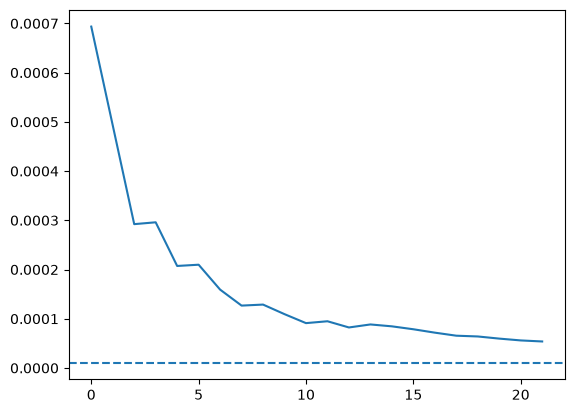

In [44]:
out = []
for k in range(1, len(UNIVERSE)):
    out.append(calc_floor_performance(MARKET_CAPS, SIGMA_AUG, k))

plt.plot(out)
plt.axhline(y=optimal_performance, linestyle='--')

In [39]:
raw_spy = yf.Ticker("SPY")


raw_spy.funds_data.top_holdings

,Name,Holding Percent
Symbol,,
NVDA,NVIDIA Corp,0.078911
AAPL,Apple Inc,0.070463
MSFT,Microsoft Corp,0.051420
AMZN,Amazon.com Inc,0.040662
GOOGL,Alphabet Inc Class A,0.034056
AVGO,Broadcom Inc,0.032578
GOOG,Alphabet Inc Class C,0.027075
META,Meta Platforms Inc Class A,0.021276
TSLA,Tesla Inc,0.018849
